# Time-feature interactions

Plan: `time_feature_interaction_plan.md` (same folder). Hypothesis: the generator changes across pockets of categorical combinations; the time features either take part in those pockets or are noise. This notebook runs modules M1-M7 from the plan and ends with a decision table. Verdicts follow the pre-registered rule: observed MI must beat the best of 10 shuffled-label MI values by 10%, and the effect size must clear its floor (Cramer's V >= 0.02, epsilon-squared / eta-squared >= 0.005).


In [1]:
%load_ext autoreload
%autoreload 2

import importlib
import json
import sys
from ccf_ml import file_utils
from ccf_ml.cross_validation import alarm as alarm_mod
importlib.reload(file_utils)
importlib.reload(alarm_mod)

from ccf_ml.cross_validation.alarm import alarm_flag_mask
from ccf_ml.cross_validation.constants import (
    ALARM_FLAG_COLUMNS,
    ID_COLUMN,
    TARGET_COLUMN,
)
from ccf_ml.file_utils import (
    get_repo_root,
    get_script_plot_dir,
    get_script_table_dir,
    get_train_csv_path,
    get_training_config_path,
    get_training_oof_path,
)
from scipy.stats import chi2_contingency, chisquare, kruskal
from sklearn.metrics import mutual_info_score, roc_auc_score
from tqdm.auto import tqdm
import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.insert(0, str(get_repo_root() / "experiments" / "baselines"))
from features import CATEGORICAL_COLUMNS, NUMERIC_COLUMNS, prepare_features

DELIMITER_VALUE = "-" * 50
NOTEBOOK_STEM = "time_feature_interactions"
EXP_NAME = "hgb_baseline"
HOUR_COL = "time_of_day_hour"
DOW_COL = "day_of_week"
TIME_COLUMNS = (HOUR_COL, DOW_COL)
MERCHANT_COL = "merchant_category"
AGE_COL = "customer_age"
KEY_NUMERIC_COLUMNS = ("amount_usd", "velocity_score", "merchant_risk_score", AGE_COL)
N_PERM = 10
MI_MARGIN = 1.1
V_FLOOR = 0.02
EFFECT_STRONG = 0.05
ETA_FLOOR = 0.005
tables_dir = get_script_table_dir(NOTEBOOK_STEM)

train_df = pd.read_csv(get_train_csv_path())
frame = train_df.copy()
has_alarm = alarm_flag_mask(frame, columns=ALARM_FLAG_COLUMNS)
time_cell = frame[HOUR_COL].astype(str) + "_" + frame[DOW_COL].astype(str)
REGIONS = {
    "all": np.ones(len(frame), dtype=bool),
    "alarm": has_alarm.to_numpy(dtype=bool),
    "no_alarm": (~has_alarm.to_numpy(dtype=bool)),
}
for name, mask in REGIONS.items():
    part = frame.loc[mask]
    print(name, len(part), int(part[TARGET_COLUMN].sum()))


def entropy(labels) -> float:
    return float(mutual_info_score(labels, labels))


def chi2_independence(left, right):
    table = pd.crosstab(left, right)
    chi2, p_value, dof, _ = chi2_contingency(table)
    n = float(table.to_numpy().sum())
    k = min(table.shape) - 1
    if k == 0:
        return 0.0, 1.0, 0, 0.0
    cramers_v = float(np.sqrt(chi2 / (n * k)))
    return float(chi2), float(p_value), int(dof), cramers_v


def mi_vs_null(left, right, n_perm=N_PERM, seed=0):
    observed = float(mutual_info_score(left, right))
    rng = np.random.default_rng(seed)
    right_arr = np.asarray(right)
    null = np.empty(n_perm, dtype=np.float64)
    for i in range(n_perm):
        null[i] = float(mutual_info_score(left, rng.permutation(right_arr)))
    return observed, null


def interaction_verdict(observed, null_max, effect, floor):
    beats_null = observed > MI_MARGIN * float(null_max)
    if not beats_null:
        return "independent"
    if effect < floor:
        return "detectable_not_exploitable"
    if effect < EFFECT_STRONG:
        return "weak"
    return "strong"


decision_records: list[dict[str, object]] = []


def record(
    module,
    feature,
    region,
    time_view,
    observed_mi,
    null_mi_max,
    effect_name,
    effect_value,
    verdict,
):
    decision_records.append(
        {
            "module": module,
            "feature": feature,
            "region": region,
            "time_view": time_view,
            "observed_mi": observed_mi,
            "null_mi_max": null_mi_max,
            "effect_name": effect_name,
            "effect_value": effect_value,
            "verdict": verdict,
        }
    )


all 699960 11689
alarm 53022 4758
no_alarm 646938 6931


## M1: are transaction counts uniform over the clock?

Counts per hour, per day, and per 7 x 24 cell against a uniform expectation, plus hour x day independence. Descriptive only: an uneven clock describes the count process, not fraud.


         view  n_cells  expected_per_cell  min_count  max_count  min_rel_dev  max_rel_dev      chi2  p_value  cramers_v_vs_uniform
         hour       24         29165.0000      25806      33994      -0.1152       0.1656 3602.3499      0.0                0.0717
  day_of_week        7         99994.2857      95271     102508      -0.0472       0.0251  442.2595      0.0                0.0251
hour_day_cell      168          4166.4286       3450       4995      -0.1720       0.1989 4213.0138      0.0                0.0776
--------------------------------------------------
hour x day_of_week independence: chi2=168.0 dof=138 p=0.04206 V=0.0063
saved C:\Users\bouab\ayhem-personal\DEV\ML\DL_projects\kaggle_comps\CreditCardFraud\storage\artifacts\time_feature_interactions\tables\uniformity_tests.csv
saved C:\Users\bouab\ayhem-personal\DEV\ML\DL_projects\kaggle_comps\CreditCardFraud\storage\artifacts\time_feature_interactions\plots\m1_uniformity\counts_uniformity.png


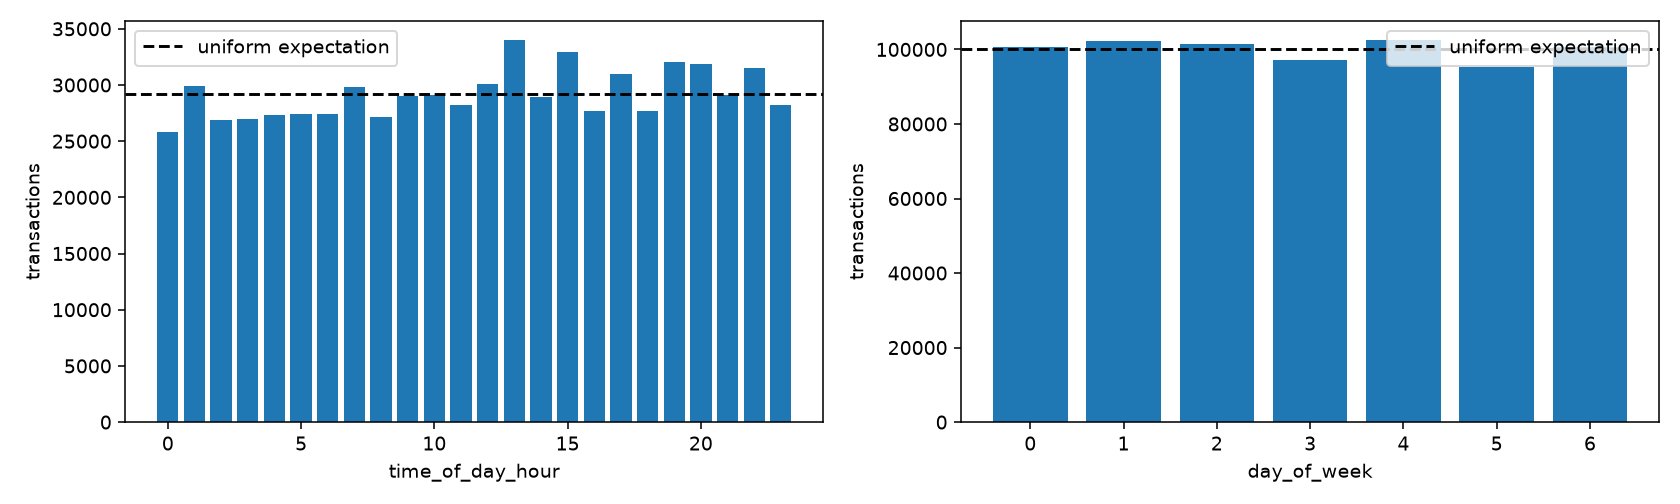

In [2]:
uniformity_rows: list[dict[str, object] | None] = [None] * 3
views = (
    ("hour", frame[HOUR_COL].value_counts().sort_index(), 24),
    ("day_of_week", frame[DOW_COL].value_counts().sort_index(), 7),
    ("hour_day_cell", time_cell.value_counts().sort_index(), 168),
)
for i, (name, counts, n_cells) in enumerate(views):
    expected = len(frame) / n_cells
    counts_arr = counts.to_numpy(dtype=np.float64)
    rel_dev = (counts_arr - expected) / expected
    chi2, p_value = chisquare(counts_arr, f_exp=np.full(n_cells, expected))
    uniformity_rows[i] = {
        "view": name,
        "n_cells": n_cells,
        "expected_per_cell": expected,
        "min_count": int(counts_arr.min()),
        "max_count": int(counts_arr.max()),
        "min_rel_dev": float(rel_dev.min()),
        "max_rel_dev": float(rel_dev.max()),
        "chi2": float(chi2),
        "p_value": float(p_value),
        "cramers_v_vs_uniform": float(np.sqrt(chi2 / len(frame))),
    }
uniformity_table = pd.DataFrame([row for row in uniformity_rows if row is not None])
print(uniformity_table.round(4).to_string(index=False))
print(DELIMITER_VALUE)
chi2_hd, p_hd, dof_hd, v_hd = chi2_independence(frame[HOUR_COL], frame[DOW_COL])
print(f"hour x day_of_week independence: chi2={chi2_hd:.1f} dof={dof_hd} p={p_hd:.4g} V={v_hd:.4f}")
uniformity_path = tables_dir / "uniformity_tests.csv"
uniformity_table.to_csv(uniformity_path, index=False)
print("saved", uniformity_path)

plot_dir = get_script_plot_dir(NOTEBOOK_STEM, section="m1_uniformity")
fig, axes = plt.subplots(1, 2, figsize=(12.0, 3.6))
axes[0].bar(np.arange(24), frame[HOUR_COL].value_counts().sort_index().to_numpy())
axes[0].axhline(len(frame) / 24, color="black", linestyle="--", label="uniform expectation")
axes[0].set_xlabel(HOUR_COL)
axes[0].set_ylabel("transactions")
axes[0].legend()
axes[1].bar(np.arange(7), frame[DOW_COL].value_counts().sort_index().to_numpy())
axes[1].axhline(len(frame) / 7, color="black", linestyle="--", label="uniform expectation")
axes[1].set_xlabel(DOW_COL)
axes[1].set_ylabel("transactions")
axes[1].legend()
fig.tight_layout()
counts_plot = plot_dir / "counts_uniformity.png"
fig.savefig(counts_plot, dpi=140)
print("saved", counts_plot)
plt.show()


## M2: does fraud depend on time?

Fraud rate by hour for all / alarm / no-alarm, chi-square and MI for hour, day, and joint cell. Global gets all three views; the regions get hour and joint cell.


  region     time_view      n  n_fraud    rate      chi2  p_value  cramers_v  mi_nats  null_mi_max  mi_share_of_label     verdict
     all          hour 699960    11689 0.01670  31.11879  0.11990    0.00667  0.00002      0.00003            0.00026 independent
     all   day_of_week 699960    11689 0.01670  13.26418  0.03903    0.00435  0.00001      0.00001            0.00011 independent
     all hour_day_cell 699960    11689 0.01670 156.42282  0.71047    0.01495  0.00011      0.00015            0.00133 independent
   alarm          hour  53022     4758 0.08974  31.10450  0.12025    0.02422  0.00030      0.00032            0.00098 independent
   alarm   day_of_week  53022     4758 0.08974  10.10533  0.12029    0.01381  0.00010      0.00019            0.00032 independent
   alarm hour_day_cell  53022     4758 0.08974 147.30384  0.86135    0.05271  0.00140      0.00201            0.00463 independent
no_alarm          hour 646938     6931 0.01071  21.88737  0.52706    0.00582  0.00002     

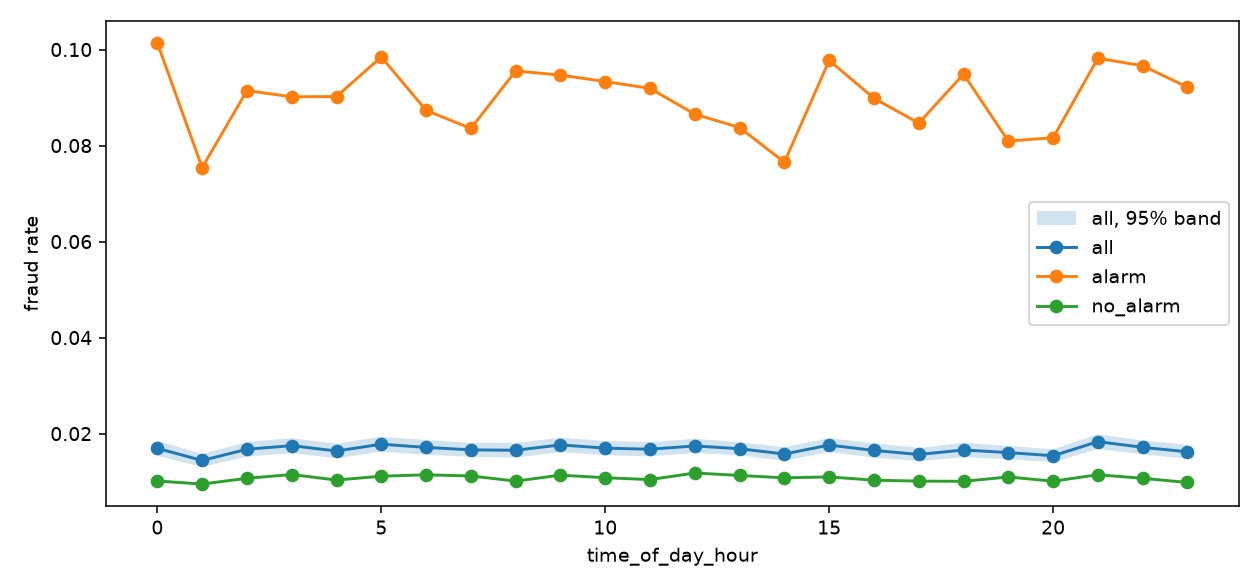

In [3]:
fraud_rows: list[dict[str, object]] = []
for region_name, mask in REGIONS.items():
    y = frame.loc[mask, TARGET_COLUMN]
    h_y = entropy(y)
    views = (
        ("hour", frame.loc[mask, HOUR_COL]),
        ("day_of_week", frame.loc[mask, DOW_COL]),
        ("hour_day_cell", time_cell.loc[mask]),
    )
    for view_name, view in views:
        chi2, p_value, dof, v = chi2_independence(y, view)
        observed, null = mi_vs_null(y, view)
        verdict = interaction_verdict(observed, null.max(), v, V_FLOOR)
        fraud_rows.append(
            {
                "region": region_name,
                "time_view": view_name,
                "n": int(mask.sum()),
                "n_fraud": int(y.sum()),
                "rate": float(y.mean()),
                "chi2": chi2,
                "p_value": p_value,
                "cramers_v": v,
                "mi_nats": observed,
                "null_mi_max": float(null.max()),
                "mi_share_of_label": observed / h_y,
                "verdict": verdict,
            }
        )
        record("M2_fraud", "is_fraud", region_name, view_name, observed, float(null.max()), "cramers_v", v, verdict)
fraud_table = pd.DataFrame(fraud_rows)
print(fraud_table.round(5).to_string(index=False))
fraud_path = tables_dir / "fraud_time_tests.csv"
fraud_table.to_csv(fraud_path, index=False)
print("saved", fraud_path)

plot_dir = get_script_plot_dir(NOTEBOOK_STEM, section="m2_fraud")
fig, ax = plt.subplots(figsize=(9.0, 4.2))
hours = np.arange(24)
global_hourly = (
    frame.groupby(HOUR_COL)[TARGET_COLUMN]
    .agg(["mean", "size"])
    .reindex(range(24))
)
se = np.sqrt(
    global_hourly["mean"] * (1.0 - global_hourly["mean"]) / global_hourly["size"]
)
ax.fill_between(
    hours,
    global_hourly["mean"] - 1.96 * se,
    global_hourly["mean"] + 1.96 * se,
    alpha=0.2,
    label="all, 95% band",
)
for region_name, mask in REGIONS.items():
    rates = (
        frame.loc[mask]
        .groupby(HOUR_COL)[TARGET_COLUMN]
        .mean()
        .reindex(range(24))
    )
    ax.plot(hours, rates, marker="o", label=region_name)
ax.set_xlabel(HOUR_COL)
ax.set_ylabel("fraud rate")
ax.legend()
fig.tight_layout()
rate_plot = plot_dir / "fraud_rate_by_hour.png"
fig.savefig(rate_plot, dpi=140)
print("saved", rate_plot)
plt.show()


## M3: do categorical features depend on time?

Each categorical column against the joint 7 x 24 cell (MI vs shuffle null, chi-square, Cramer's V). Merchant additionally per region on the hour view. The heatmap is the merchant lift `P(merchant | hour) / P(merchant)` on the full train.


                     feature   region     time_view  mi_nats  null_mi_max  mi_share_of_feature  p_value  cramers_v                    verdict
is_ai_generated_scam_attempt      all hour_day_cell  0.00012      0.00013              0.00528  0.72114    0.01492                independent
   billing_shipping_mismatch      all hour_day_cell  0.00014      0.00015              0.00199  0.07797    0.01663                independent
      is_foreign_transaction      all hour_day_cell  0.00011      0.00015              0.00131  0.64797    0.01510                independent
         ip_country_mismatch      all hour_day_cell  0.00010      0.00014              0.00122  0.93117    0.01418                independent
           merchant_category    alarm          hour  0.00254      0.00299              0.00116  0.23952    0.02146                independent
                    used_vpn      all hour_day_cell  0.00013      0.00014              0.00086  0.27214    0.01593                independent
      

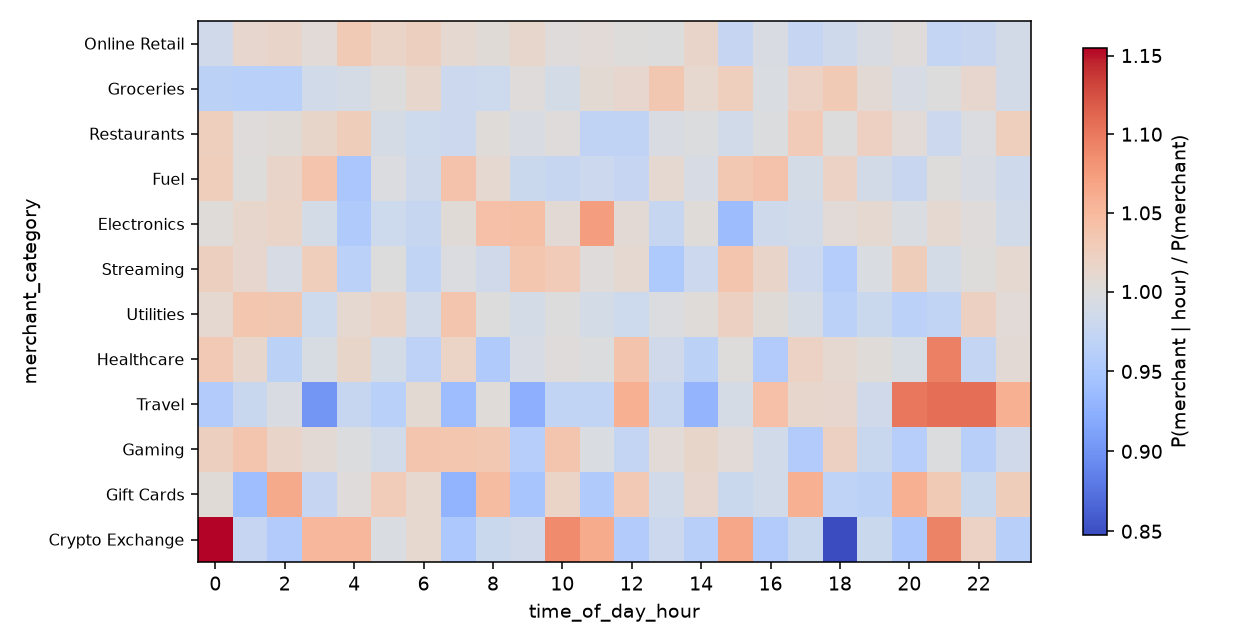

In [4]:
cat_rows: list[dict[str, object]] = []
for col in tqdm(list(CATEGORICAL_COLUMNS), desc="categorical x time cell"):
    h_col = entropy(frame[col])
    observed, null = mi_vs_null(frame[col], time_cell)
    chi2, p_value, dof, v = chi2_independence(frame[col], time_cell)
    verdict = interaction_verdict(observed, null.max(), v, V_FLOOR)
    cat_rows.append(
        {
            "feature": col,
            "region": "all",
            "time_view": "hour_day_cell",
            "mi_nats": observed,
            "null_mi_max": float(null.max()),
            "mi_share_of_feature": observed / h_col,
            "chi2": chi2,
            "p_value": p_value,
            "cramers_v": v,
            "verdict": verdict,
        }
    )
    record("M3_categorical", col, "all", "hour_day_cell", observed, float(null.max()), "cramers_v", v, verdict)
for region_name in ("alarm", "no_alarm"):
    mask = REGIONS[region_name]
    observed, null = mi_vs_null(frame.loc[mask, MERCHANT_COL], frame.loc[mask, HOUR_COL])
    chi2, p_value, dof, v = chi2_independence(frame.loc[mask, MERCHANT_COL], frame.loc[mask, HOUR_COL])
    h_col = entropy(frame.loc[mask, MERCHANT_COL])
    verdict = interaction_verdict(observed, null.max(), v, V_FLOOR)
    cat_rows.append(
        {
            "feature": MERCHANT_COL,
            "region": region_name,
            "time_view": "hour",
            "mi_nats": observed,
            "null_mi_max": float(null.max()),
            "mi_share_of_feature": observed / h_col,
            "chi2": chi2,
            "p_value": p_value,
            "cramers_v": v,
            "verdict": verdict,
        }
    )
    record("M3_categorical", MERCHANT_COL, region_name, "hour", observed, float(null.max()), "cramers_v", v, verdict)
cat_table = pd.DataFrame(cat_rows).sort_values("mi_share_of_feature", ascending=False)
print(cat_table.drop(columns=["chi2"]).round(5).to_string(index=False))
cat_path = tables_dir / "cat_time_tests.csv"
cat_table.to_csv(cat_path, index=False)
print("saved", cat_path)

from matplotlib.colors import TwoSlopeNorm

merchant_share = frame[MERCHANT_COL].value_counts(normalize=True)
merchant_given_hour = pd.crosstab(frame[HOUR_COL], frame[MERCHANT_COL], normalize="index")
lift = merchant_given_hour.div(merchant_share, axis=1).reindex(
    index=range(24), columns=merchant_share.index
)
if lift.isna().to_numpy().any():
    raise ValueError("lift grid has empty hour or merchant cells")
plot_dir = get_script_plot_dir(NOTEBOOK_STEM, section="m3_categorical")
fig, ax = plt.subplots(figsize=(9.0, 4.6))
im = ax.imshow(
    lift.to_numpy(dtype=np.float64).T,
    aspect="auto",
    cmap="coolwarm",
    norm=TwoSlopeNorm(vcenter=1.0),
)
ax.set_xticks(np.arange(0, 24, 2))
ax.set_xlabel(HOUR_COL)
ax.set_yticks(np.arange(len(merchant_share.index)))
ax.set_yticklabels(list(merchant_share.index), fontsize=8)
ax.set_ylabel(MERCHANT_COL)
fig.colorbar(im, ax=ax, shrink=0.9, label="P(merchant | hour) / P(merchant)")
fig.tight_layout()
lift_plot = plot_dir / "merchant_by_hour_lift_global.png"
fig.savefig(lift_plot, dpi=140)
print("saved", lift_plot)
plt.show()


## M4: do numeric features depend on time?

Each numeric feature (time columns excluded) in deciles against the joint time cell (MI vs shuffle null), plus Kruskal-Wallis across the 24 hours with effect size epsilon-squared. The four key numerics also get per-hour mean z-scores (money on the log scale) and per-region MI on the hour view.


              feature   region     time_view  mi_nats  null_mi_max  epsilon_sq                    verdict
           amount_usd      all hour_day_cell  0.00130      0.00112     0.00001 detectable_not_exploitable
 hours_since_last_txn      all hour_day_cell  0.00111      0.00113     0.00002                independent
   txn_count_last_24h      all hour_day_cell  0.00068      0.00064     0.00003                independent
distance_from_home_km      all hour_day_cell  0.00107      0.00115     0.00000                independent
      card_age_months      all hour_day_cell  0.00107      0.00110     0.00000                independent
         customer_age      all hour_day_cell  0.00106      0.00114     0.00000                independent
  account_balance_usd      all hour_day_cell  0.00114      0.00111     0.00000                independent
      cvv_retry_count      all hour_day_cell  0.00000      0.00000     0.00000                independent
       velocity_score      all hour_day_cell  

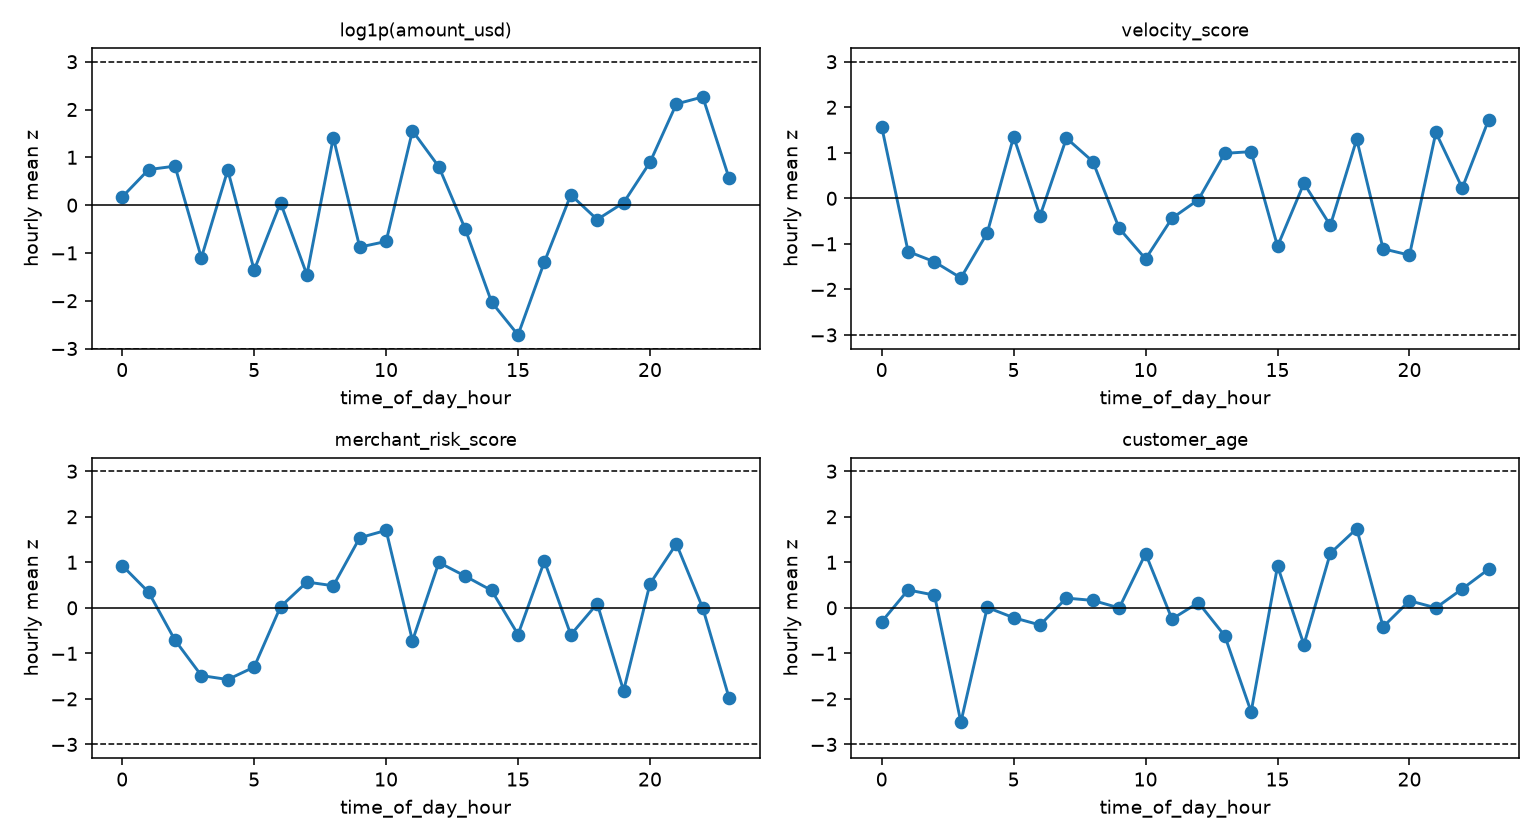

In [5]:
numeric_cols = [c for c in NUMERIC_COLUMNS if c not in TIME_COLUMNS]
numeric_rows: list[dict[str, object]] = []
for col in tqdm(numeric_cols, desc="numeric x time cell"):
    dec = pd.qcut(frame[col], 10, labels=False, duplicates="drop")
    if int(dec.nunique()) < 2:
        numeric_rows.append(
            {
                "feature": col,
                "region": "all",
                "time_view": "hour_day_cell",
                "mi_nats": 0.0,
                "null_mi_max": 0.0,
                "epsilon_sq": 0.0,
                "verdict": "independent",
            }
        )
        record("M4_numeric", col, "all", "hour_day_cell", 0.0, 0.0, "epsilon_sq", 0.0, "independent")
        continue
    observed, null = mi_vs_null(dec, time_cell)
    groups = [frame.loc[frame[HOUR_COL] == h, col].to_numpy() for h in range(24)]
    h_stat, _p_kw = kruskal(*groups)
    epsilon_sq = max((float(h_stat) - 24.0 + 1.0) / (len(frame) - 24.0), 0.0)
    verdict = interaction_verdict(observed, null.max(), epsilon_sq, ETA_FLOOR)
    numeric_rows.append(
        {
            "feature": col,
            "region": "all",
            "time_view": "hour_day_cell",
            "mi_nats": observed,
            "null_mi_max": float(null.max()),
            "epsilon_sq": epsilon_sq,
            "verdict": verdict,
        }
    )
    record("M4_numeric", col, "all", "hour_day_cell", observed, float(null.max()), "epsilon_sq", epsilon_sq, verdict)
for col in KEY_NUMERIC_COLUMNS:
    for region_name in ("alarm", "no_alarm"):
        mask = REGIONS[region_name]
        dec = pd.qcut(frame.loc[mask, col], 10, labels=False, duplicates="drop")
        observed, null = mi_vs_null(dec, frame.loc[mask, HOUR_COL])
        _chi2, _p, _dof, v = chi2_independence(dec, frame.loc[mask, HOUR_COL])
        verdict = interaction_verdict(observed, null.max(), v, V_FLOOR)
        numeric_rows.append(
            {
                "feature": col,
                "region": region_name,
                "time_view": "hour",
                "mi_nats": observed,
                "null_mi_max": float(null.max()),
                "epsilon_sq": v,
                "verdict": verdict,
            }
        )
        record("M4_numeric", col, region_name, "hour", observed, float(null.max()), "cramers_v", v, verdict)
numeric_table = pd.DataFrame(numeric_rows)
print(numeric_table.round(5).to_string(index=False))
numeric_path = tables_dir / "numeric_time_tests.csv"
numeric_table.to_csv(numeric_path, index=False)
print("saved", numeric_path)

plot_dir = get_script_plot_dir(NOTEBOOK_STEM, section="m4_numeric")
fig, axes = plt.subplots(2, 2, figsize=(11.0, 6.0))
for ax, col in zip(axes.ravel(), KEY_NUMERIC_COLUMNS):
    if col == "amount_usd":
        x = np.log1p(frame[col])
        label = f"log1p({col})"
    else:
        x = frame[col]
        label = col
    glob_mean = float(x.mean())
    glob_sd = float(x.std())
    grouped = x.groupby(frame[HOUR_COL]).agg(["mean", "size"])
    z = (grouped["mean"] - glob_mean) / (glob_sd / np.sqrt(grouped["size"]))
    ax.plot(np.arange(24), z, marker="o")
    ax.axhline(0.0, color="black", linewidth=0.8)
    ax.axhline(3.0, color="black", linestyle="--", linewidth=0.8)
    ax.axhline(-3.0, color="black", linestyle="--", linewidth=0.8)
    ax.set_xlabel(HOUR_COL)
    ax.set_ylabel("hourly mean z")
    ax.set_title(label, fontsize=9)
fig.tight_layout()
z_plot = plot_dir / "numeric_hour_z.png"
fig.savefig(z_plot, dpi=140)
print("saved", z_plot)
plt.show()


## M5: does customer age depend on time?

Age in deciles against the hour (MI vs shuffle null), plus eta-squared: the share of age variance explained by the hour-of-day group means. If this passes, the "customer's age minus the average age at that time" feature is a candidate; otherwise the idea is dropped.


  region  mi_nats  null_mi_max  eta_sq     verdict  cramers_v
     all  0.00012      0.00017 0.00003 independent        NaN
   alarm  0.00165      0.00212     NaN independent    0.01918
no_alarm  0.00013      0.00019     NaN independent    0.00545
saved C:\Users\bouab\ayhem-personal\DEV\ML\DL_projects\kaggle_comps\CreditCardFraud\storage\artifacts\time_feature_interactions\tables\age_time_tests.csv
age deviation feature: DROP THE IDEA (age does not depend on hour)
saved C:\Users\bouab\ayhem-personal\DEV\ML\DL_projects\kaggle_comps\CreditCardFraud\storage\artifacts\time_feature_interactions\plots\m5_age\mean_age_by_hour.png


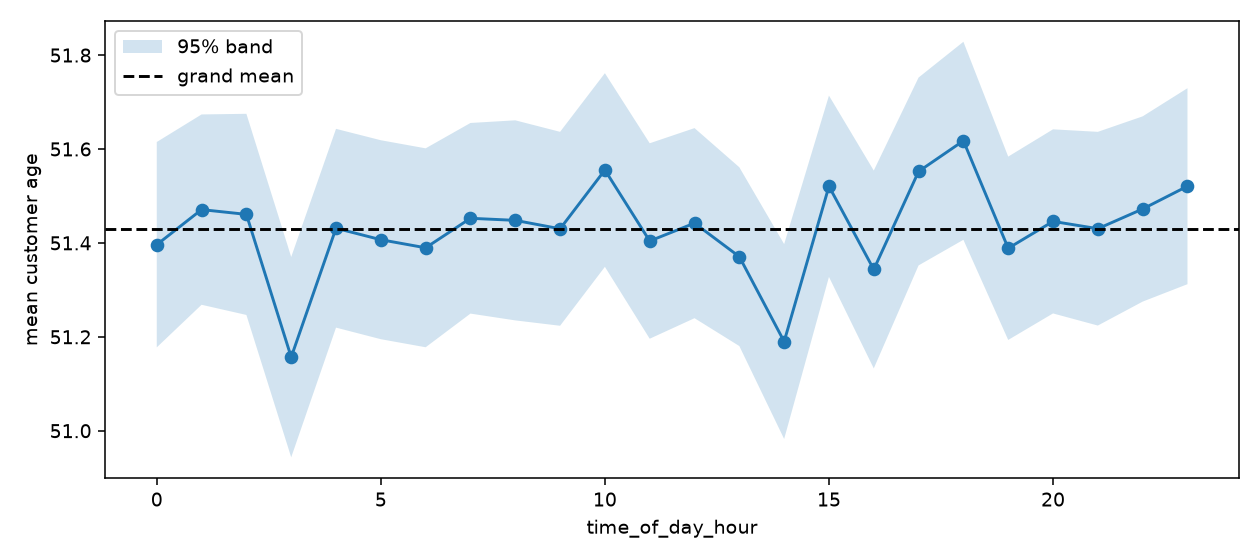

In [6]:
age_dec = pd.qcut(frame[AGE_COL], 10, labels=False, duplicates="drop")
age_rows: list[dict[str, object]] = []
grand_mean = float(frame[AGE_COL].mean())
grouped_age = frame.groupby(HOUR_COL)[AGE_COL].agg(["mean", "size", "std"])
ss_between = float((grouped_age["size"] * (grouped_age["mean"] - grand_mean) ** 2).sum())
ss_total = float(((frame[AGE_COL] - grand_mean) ** 2).sum())
eta_sq = ss_between / ss_total
for region_name, mask in list(REGIONS.items()):
    dec = pd.qcut(frame.loc[mask, AGE_COL], 10, labels=False, duplicates="drop") if region_name != "all" else age_dec
    observed, null = mi_vs_null(dec, frame.loc[mask, HOUR_COL])
    if region_name == "all":
        effect, floor = eta_sq, ETA_FLOOR
        effect_name = "eta_sq"
    else:
        _chi2, _p, _dof, v = chi2_independence(dec, frame.loc[mask, HOUR_COL])
        effect, floor = v, V_FLOOR
        effect_name = "cramers_v"
    verdict = interaction_verdict(observed, null.max(), effect, floor)
    age_rows.append(
        {
            "region": region_name,
            "mi_nats": observed,
            "null_mi_max": float(null.max()),
            effect_name: effect,
            "verdict": verdict,
        }
    )
    record("M5_age", AGE_COL, region_name, "hour", observed, float(null.max()), effect_name, effect, verdict)
age_table = pd.DataFrame(age_rows)
print(age_table.round(5).to_string(index=False))
age_path = tables_dir / "age_time_tests.csv"
age_table.to_csv(age_path, index=False)
print("saved", age_path)
se_age = grouped_age["std"] / np.sqrt(grouped_age["size"])
if age_table.loc[age_table["region"] == "all", "verdict"].iloc[0] in ("weak", "strong"):
    print("age deviation feature: CANDIDATE (age depends on hour)")
else:
    print("age deviation feature: DROP THE IDEA (age does not depend on hour)")

plot_dir = get_script_plot_dir(NOTEBOOK_STEM, section="m5_age")
fig, ax = plt.subplots(figsize=(9.0, 4.0))
ax.plot(np.arange(24), grouped_age["mean"], marker="o")
ax.fill_between(
    np.arange(24),
    grouped_age["mean"] - 1.96 * se_age,
    grouped_age["mean"] + 1.96 * se_age,
    alpha=0.2,
    label="95% band",
)
ax.axhline(grand_mean, color="black", linestyle="--", label="grand mean")
ax.set_xlabel(HOUR_COL)
ax.set_ylabel("mean customer age")
ax.legend()
fig.tight_layout()
age_plot = plot_dir / "mean_age_by_hour.png"
fig.savefig(age_plot, dpi=140)
print("saved", age_plot)
plt.show()


## M6: does the baseline model actually use time?

Permutation check on each fold's validation rows: shuffle hour, shuffle day, shuffle both, and shuffle `merchant_risk_score` as a reference scale. The number that matters is the AUC drop.


In [7]:
oof_df = pd.read_csv(get_training_oof_path(EXP_NAME))
config = json.loads(get_training_config_path(EXP_NAME).read_text(encoding="utf-8"))
models_dir = get_repo_root() / "storage" / "artifacts" / "training" / EXP_NAME / "models"
perm_columns = (HOUR_COL, DOW_COL, "hour_and_day", "merchant_risk_score")
rng = np.random.default_rng(0)
drop_rows: list[dict[str, object]] = []
for fold_id in range(5):
    model = joblib.load(models_dir / f"fold_{fold_id}.joblib")
    val_ids = oof_df.loc[oof_df["fold_id"] == fold_id, ID_COLUMN]
    sub = frame.loc[frame[ID_COLUMN].isin(val_ids)].copy()
    features = prepare_features(sub, categories=config["categories"])
    y_true = sub[TARGET_COLUMN].to_numpy()
    base_auc = float(roc_auc_score(y_true, model.predict_proba(features)[:, 1]))
    for perm_name in perm_columns:
        permuted = features.copy()
        if perm_name == "hour_and_day":
            permuted[HOUR_COL] = rng.permutation(permuted[HOUR_COL].to_numpy())
            permuted[DOW_COL] = rng.permutation(permuted[DOW_COL].to_numpy())
        else:
            permuted[perm_name] = rng.permutation(permuted[perm_name].to_numpy())
        auc = float(roc_auc_score(y_true, model.predict_proba(permuted)[:, 1]))
        drop_rows.append(
            {
                "fold_id": fold_id,
                "permuted": perm_name,
                "base_auc": base_auc,
                "permuted_auc": auc,
                "auc_drop": base_auc - auc,
            }
        )
drop_table = pd.DataFrame(drop_rows)
model_summary = (
    drop_table.groupby("permuted")["auc_drop"]
    .agg(["mean", "std"])
    .sort_values("mean", ascending=False)
)
print(model_summary.round(6).to_string())
drop_path = tables_dir / "model_time_permutation.csv"
drop_table.to_csv(drop_path, index=False)
print("saved", drop_path)
for perm_name in perm_columns:
    mean_drop = float(model_summary.loc[perm_name, "mean"])
    if perm_name in TIME_COLUMNS or perm_name == "hour_and_day":
        if mean_drop < 0.0005:
            verdict = "unused_by_model"
        elif mean_drop < 0.002:
            verdict = "barely_used"
        else:
            verdict = "used"
        record("M6_model", perm_name, "all", "permutation", mean_drop, 0.0, "auc_drop", mean_drop, verdict)


                         mean       std
permuted                               
merchant_risk_score  0.077344  0.006393
day_of_week          0.000046  0.000147
time_of_day_hour     0.000046  0.000133
hour_and_day        -0.000024  0.000157
saved C:\Users\bouab\ayhem-personal\DEV\ML\DL_projects\kaggle_comps\CreditCardFraud\storage\artifacts\time_feature_interactions\tables\model_time_permutation.csv


## M7: decision table

Every test in one table with the pre-registered verdicts and the suggested action.


In [8]:
ACTION_BY_VERDICT = {
    "independent": "drop candidate",
    "detectable_not_exploitable": "drop candidate (effect too small)",
    "weak": "bucket / interaction candidate",
    "strong": "distill: bucket + interactions",
    "unused_by_model": "drop candidate",
    "barely_used": "drop candidate",
    "used": "keep raw",
}
decision_table = pd.DataFrame(decision_records)
decision_table["suggested_action"] = decision_table["verdict"].map(ACTION_BY_VERDICT)
decision_table = decision_table.sort_values(["module", "feature", "region"]).reset_index(drop=True)
decision_path = tables_dir / "decision_table.csv"
decision_table.to_csv(decision_path, index=False)
print("saved", decision_path)
print(DELIMITER_VALUE)
print(decision_table.round(5).to_string(index=False))
print(DELIMITER_VALUE)
print(decision_table.groupby("verdict").size().to_string())
print(DELIMITER_VALUE)
time_verdicts = decision_table.loc[
    decision_table["module"].isin(["M2_fraud", "M3_categorical", "M4_numeric", "M5_age", "M6_model"])
]
print("verdict counts for time-related tests")
print(time_verdicts.groupby("verdict").size().to_string())


saved C:\Users\bouab\ayhem-personal\DEV\ML\DL_projects\kaggle_comps\CreditCardFraud\storage\artifacts\time_feature_interactions\tables\decision_table.csv
--------------------------------------------------
        module                      feature   region     time_view  observed_mi  null_mi_max effect_name  effect_value                    verdict                  suggested_action
      M2_fraud                     is_fraud    alarm          hour      0.00030      0.00032   cramers_v       0.02422                independent                    drop candidate
      M2_fraud                     is_fraud    alarm   day_of_week      0.00010      0.00019   cramers_v       0.01381                independent                    drop candidate
      M2_fraud                     is_fraud    alarm hour_day_cell      0.00140      0.00201   cramers_v       0.05271                independent                    drop candidate
      M2_fraud                     is_fraud      all          hour      0.0

## Takeaway

1. **The clock is busy/quiet, but nothing else.** Transaction counts are not exactly uniform: hour cells deviate up to -11.5% / +16.6% from the even expectation (day-of-week: -4.7% / +2.5%), and hour is independent of day (V=0.006). This is occupancy only; it carries no fraud or feature information.

2. **Fraud is independent of time everywhere.** all / alarm / no-alarm x hour / day / joint cell: the observed MI never beats the shuffled null. The fraud-rate-by-hour lines are flat inside their bands.

3. **Categoricals are independent of time, except one ripple.** merchant_category is `detectable_not_exploitable`: real MI (0.00156 nats vs 0.00137 null max) but Cramer's V=0.017 — 1-2% lift ripples, too small to use.

4. **Numerics are independent of time, except the same kind of ripple on amount_usd** (MI beats the null barely; epsilon-squared = 0.00001).

5. **Age does not depend on hour** (eta-squared = 0.00003 on the full train). The "customer's age minus the average age at that hour" feature is dropped, not built.

6. **The model agrees it is dead weight.** Per-fold permutation on validation rows: shuffling hour or day moves AUC by ~0.00005 (both together: -0.00002, pure noise), while shuffling `merchant_risk_score` costs **0.0773** AUC.

7. **Decision (per the pre-registered rule): drop the raw time features from the model.** Final tally: 41 independent, 3 detectable-not-exploitable (merchant, amount), 3 unused-by-model; zero weak, zero strong. Confirmation step before deletion: retrain the baseline without the two columns and check the OOF AUC stays at 0.942.

## M4b: per-cell distribution profiles (repaired)

Spec and repair are pre-registered in the plan doc. Each of the 168 time cells holds ~4.2k rows. Continuous features get per-cell mean, sd, usable quantile levels, IQR, and robust range, each standardized by its sampling error under independence; a level is usable only when the pooled window q(p-1%)..q(p+1%) holds >= 10 distinct values. Integral-valued features move to M4c. Every statistic is also computed on one shuffled-time pass, and a flag requires excess dispersion beating both the analytic band (VR > 1.33) and the shuffled pass (VR > VR_null + 0.33), or max |z| > 4.5 while the null stays <= 4.5.


continuous (quantile machinery): ['amount_usd', 'hours_since_last_txn', 'distance_from_home_km', 'account_balance_usd', 'velocity_score', 'merchant_risk_score']
integral (M4c value counting): ['txn_count_last_24h', 'card_age_months', 'customer_age', 'cvv_retry_count', 'prior_disputes']
expected max |z| of 168 standard-normal draws: 3.20
--------------------------------------------------
amount_usd: usable quantile levels 9/9
hours_since_last_txn: usable quantile levels 9/9
distance_from_home_km: usable quantile levels 9/9
account_balance_usd: usable quantile levels 9/9
velocity_score: usable quantile levels 4/9, iqr dropped, robust range dropped
merchant_risk_score: usable quantile levels 7/9, iqr dropped
saved C:\Users\bouab\ayhem-personal\DEV\ML\DL_projects\kaggle_comps\CreditCardFraud\storage\artifacts\time_feature_interactions\tables\m4b_quantile_moment_tests.csv
--------------------------------------------------
worst statistic per feature (by observed variance ratio)
            

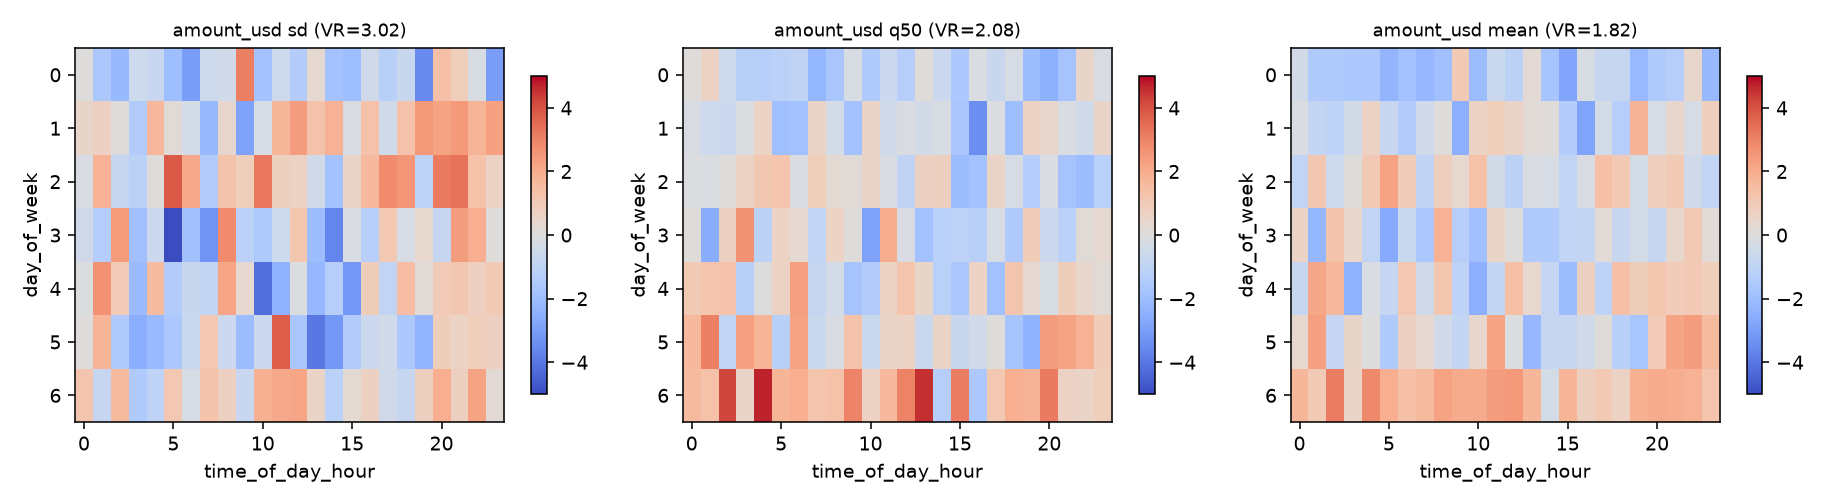

In [9]:
numeric_cols = [c for c in NUMERIC_COLUMNS if c not in TIME_COLUMNS]
M4B_P_LEVELS = (0.01, 0.05, 0.10, 0.25, 0.50, 0.75, 0.90, 0.95, 0.99)
M4B_VR_EXCESS = 1.33
M4B_MAX_Z = 4.5
M4B_LOCAL_WINDOW = 0.01
M4B_MIN_DISTINCT_LOCAL = 10
M4B_MONEY_LOG = ("amount_usd", "account_balance_usd")
M4B_Q_NAMES = [f"q{int(round(p * 100)):02d}" for p in M4B_P_LEVELS]


def m4b_is_integral(series) -> bool:
    vals = series.dropna().to_numpy(dtype=np.float64)
    return bool(np.all(np.equal(np.mod(vals, 1.0), 0.0)))


m4b_continuous_cols = [c for c in numeric_cols if not m4b_is_integral(frame[c])]
m4c_integral_cols = [c for c in numeric_cols if m4b_is_integral(frame[c])]
print("continuous (quantile machinery):", m4b_continuous_cols)
print("integral (M4c value counting):", m4c_integral_cols)
print(f"expected max |z| of 168 standard-normal draws: {np.sqrt(2.0 * np.log(168)):.2f}")
print(DELIMITER_VALUE)

cell_labels_arr = time_cell.to_numpy()
dow_arr = frame[DOW_COL].to_numpy()
hour_arr = frame[HOUR_COL].to_numpy()
m4b_rows: list[dict[str, object]] = []
m4b_z_store: dict[tuple[str, str], dict[tuple[int, int], float]] = {}
rng_m4b = np.random.default_rng(11)
for col in tqdm(m4b_continuous_cols, desc="m4b repaired profiles"):
    if col in M4B_MONEY_LOG:
        x = np.log1p(frame[col].to_numpy(dtype=np.float64))
        stat_scale = "log1p"
    else:
        x = frame[col].to_numpy(dtype=np.float64)
        stat_scale = "raw"
    x_sorted = np.sort(x)
    pooled_mean = float(x.mean())
    pooled_sd = float(x.std(ddof=1))
    pooled_q = np.quantile(x, M4B_P_LEVELS)
    grid = np.linspace(0.005, 0.995, 199)
    q_grid = np.quantile(x, grid)
    dq = np.gradient(q_grid, grid)
    f_at = np.interp(M4B_P_LEVELS, grid, 1.0 / np.maximum(dq, 1e-12))
    var_q = np.array([p * (1.0 - p) / (f_at[i] ** 2) for i, p in enumerate(M4B_P_LEVELS)])
    usable = []
    for p in M4B_P_LEVELS:
        q_lo = np.quantile(x, max(p - M4B_LOCAL_WINDOW, 0.001))
        q_hi = np.quantile(x, min(p + M4B_LOCAL_WINDOW, 0.999))
        i_lo = int(np.searchsorted(x_sorted, q_lo, side="left"))
        i_hi = int(np.searchsorted(x_sorted, q_hi, side="right"))
        n_distinct = int(np.unique(x_sorted[i_lo:i_hi]).size)
        usable.append(n_distinct >= M4B_MIN_DISTINCT_LOCAL)
    idx = {int(round(p * 100)): i for i, p in enumerate(M4B_P_LEVELS)}
    iqr_ok = usable[idx[25]] and usable[idx[75]]
    range_ok = usable[idx[1]] and usable[idx[99]]

    def pair_var(a: int, b: int) -> float:
        pa, pb = M4B_P_LEVELS[a], M4B_P_LEVELS[b]
        cov = pa * (1.0 - pb) / (f_at[a] * f_at[b])
        return var_q[a] + var_q[b] - 2.0 * cov

    iqr_var = pair_var(idx[25], idx[75])
    range_var = pair_var(idx[1], idx[99])
    stat_names = (
        ["mean", "sd"]
        + [M4B_Q_NAMES[i] for i in range(len(M4B_P_LEVELS)) if usable[i]]
        + (["iqr"] if iqr_ok else [])
        + (["range_q99_q01"] if range_ok else [])
    )
    print(
        f"{col}: usable quantile levels {sum(usable)}/{len(M4B_P_LEVELS)}"
        + ("" if iqr_ok else ", iqr dropped")
        + ("" if range_ok else ", robust range dropped")
    )

    def profile_pass(labels: np.ndarray):
        order = np.argsort(labels, kind="stable")
        sorted_labels = labels[order]
        boundaries = np.flatnonzero(
            np.r_[True, sorted_labels[1:] != sorted_labels[:-1]]
        )
        group_ends = np.r_[boundaries[1:], len(labels)]
        n_groups = len(boundaries)
        out = {name: np.full(n_groups, np.nan, dtype=np.float64) for name in stat_names}
        cell_ids: list[tuple[int, int]] = []
        for gi in range(n_groups):
            pos = order[boundaries[gi] : group_ends[gi]]
            n_c = int(len(pos))
            cell_ids.append((int(dow_arr[pos[0]]), int(hour_arr[pos[0]])))
            vals = x[pos]
            out["mean"][gi] = (vals.mean() - pooled_mean) * np.sqrt(n_c) / pooled_sd
            cell_sd = float(vals.std(ddof=1))
            out["sd"][gi] = (cell_sd - pooled_sd) * np.sqrt(2.0 * n_c) / pooled_sd
            cq = np.quantile(vals, M4B_P_LEVELS)
            for i, p in enumerate(M4B_P_LEVELS):
                if not usable[i]:
                    continue
                se = np.sqrt(p * (1.0 - p) / n_c) / f_at[i]
                out[M4B_Q_NAMES[i]][gi] = (cq[i] - pooled_q[i]) / se
            if iqr_ok:
                out["iqr"][gi] = (
                    (cq[idx[75]] - cq[idx[25]])
                    - (pooled_q[idx[75]] - pooled_q[idx[25]])
                ) / np.sqrt(max(iqr_var / n_c, 1e-18))
            if range_ok:
                out["range_q99_q01"][gi] = (
                    (cq[idx[99]] - cq[idx[1]])
                    - (pooled_q[idx[99]] - pooled_q[idx[1]])
                ) / np.sqrt(max(range_var / n_c, 1e-18))
        return out, cell_ids

    obs_out, cell_ids = profile_pass(cell_labels_arr)
    null_out, _ = profile_pass(rng_m4b.permutation(cell_labels_arr))
    for name in stat_names:
        z_obs = obs_out[name]
        z_null = null_out[name]
        vr_obs = float(np.mean(z_obs**2))
        vr_null = float(np.mean(z_null**2))
        max_obs = float(np.max(np.abs(z_obs)))
        max_null = float(np.max(np.abs(z_null)))
        flagged = (vr_obs > max(M4B_VR_EXCESS, vr_null + 0.33)) or (
            max_obs > M4B_MAX_Z and max_null <= M4B_MAX_Z
        )
        m4b_rows.append(
            {
                "feature": col,
                "statistic": name,
                "scale": stat_scale,
                "n_cells": len(z_obs),
                "vr_observed": vr_obs,
                "max_abs_z_observed": max_obs,
                "vr_null": vr_null,
                "max_abs_z_null": max_null,
                "flagged": flagged,
            }
        )
        m4b_z_store[(col, name)] = {
            cell_ids[gi]: float(z_obs[gi]) for gi in range(len(cell_ids))
        }

m4b_table = pd.DataFrame(m4b_rows)
m4b_path = tables_dir / "m4b_quantile_moment_tests.csv"
m4b_table.to_csv(m4b_path, index=False)
print("saved", m4b_path)
print(DELIMITER_VALUE)
worst_per_feature = m4b_table.loc[
    m4b_table.groupby("feature")["vr_observed"].idxmax()
].sort_values("vr_observed", ascending=False)
print("worst statistic per feature (by observed variance ratio)")
print(
    worst_per_feature[
        [
            "feature",
            "statistic",
            "vr_observed",
            "vr_null",
            "max_abs_z_observed",
            "flagged",
        ]
    ].round(4).to_string(index=False)
)
print(DELIMITER_VALUE)
flagged_rows = m4b_table.loc[m4b_table["flagged"]]
print("flagged (feature, statistic) pairs:", len(flagged_rows))
if len(flagged_rows):
    print(
        flagged_rows[
            ["feature", "statistic", "vr_observed", "vr_null", "max_abs_z_observed"]
        ].round(4).to_string(index=False)
    )
print(DELIMITER_VALUE)
all_z = np.concatenate(
    [np.array(list(v.values()), dtype=np.float64) for v in m4b_z_store.values()]
)
print(f"z sanity over {len(all_z)} values: mean={all_z.mean():.3f} sd={all_z.std():.3f}")

plot_dir = get_script_plot_dir(NOTEBOOK_STEM, section="m4b_profiles")
top_show = m4b_table.sort_values(
    ["flagged", "vr_observed"], ascending=[False, False]
).head(3)
n_show = len(top_show)
fig, axes = plt.subplots(1, n_show, figsize=(4.4 * n_show, 3.6))
if n_show == 1:
    axes = [axes]
for ax, (_i, row) in zip(axes, top_show.iterrows()):
    grid_z = np.full((7, 24), np.nan)
    for (dow_i, hour_i), z_val in m4b_z_store[(row["feature"], row["statistic"])].items():
        grid_z[dow_i, hour_i] = z_val
    im = ax.imshow(grid_z, aspect="auto", cmap="coolwarm", vmin=-5.0, vmax=5.0)
    ax.set_title(
        f"{row['feature']} {row['statistic']} (VR={row['vr_observed']:.2f})",
        fontsize=9,
    )
    ax.set_xlabel(HOUR_COL)
    ax.set_ylabel(DOW_COL)
    fig.colorbar(im, ax=ax, shrink=0.85)
fig.tight_layout()
m4b_plot = plot_dir / "m4b_top_deviation_heatmaps.png"
fig.savefig(m4b_plot, dpi=140)
print("saved", m4b_plot)


## Takeaway: M4b per-cell distribution profiles

1. **The yardstick is healthy.** z sanity over 11,424 values: mean -0.027, sd 1.124. The flat-level guard did its job: `velocity_score` kept only 4 of 9 quantile levels (the clamp pile at 0 is unusable; IQR and robust range dropped), `merchant_risk_score` kept 7 of 9.

2. **The sd / range artifacts of the first attempt were exactly that.** `hours_since_last_txn` sd shows VR 3.34 but the shuffled pass shows 3.13; `distance_from_home_km` robust range 3.06 vs null 3.21. Observed matches null -> approximation noise, correctly unflagged now.

3. **One real finding: `amount_usd` (log scale).** 8 of the 10 flags are amount: mean VR 1.82 vs null 0.81, median 2.08 vs 1.28, q25 1.74 vs 0.72, sd 3.02 vs 2.13. The per-cell amount distribution genuinely wiggles with the clock. The size is mild: VR ~1.5-2 on the mean and quantiles means per-cell shifts of roughly 1.2-1.4 sampling errors. `velocity_score` q95 is borderline (1.59 vs 1.20).

4. **This does not change the decision.** M4/M4b now agree that amount has a detectable but mild time association. Since fraud itself is independent of time (M2) and the baseline model ignores the time columns (M6), a per-cell amount wiggle cannot improve fraud ranking. The raw time features stay drop candidates.


## M4c: value counting for integer-valued features

Integral-valued features are counting features. Layer 1 is the omnibus net: MI on raw levels against the 7x24 cell, compared with the same 10-shuffle null as M2/M3. Layer 2 is the magnifying glass: the 10 most and 10 least common values (selected on pooled share only, testable when the expected count per cell is >= 20), each value's per-cell share standardized as a binomial z, variance ratio calibrated by one shuffled-time pass. Flags: VR > max(1.33, VR_null + 0.33) or max |z| > 4.5 while the null stays <= 4.5.


integral features (value counting): ['txn_count_last_24h', 'card_age_months', 'customer_age', 'cvv_retry_count', 'prior_disputes']
           feature  n_levels  mi_nats  null_mi_max  mi_share_of_feature        chi2  p_value  cramers_v     verdict
txn_count_last_24h        12  0.00131      0.00134              0.00073  1921.30311  0.08363    0.01580 independent
   card_age_months        49  0.00533      0.00537              0.00170  7997.58568  0.55578    0.01543 independent
      customer_age        64  0.00752      0.00763              0.00184 10494.84275  0.56980    0.01543 independent
   cvv_retry_count         4  0.00032      0.00033              0.00108   542.20080  0.09880    0.01607 independent
    prior_disputes         5  0.00036      0.00042              0.00081   613.66473  0.93454    0.01480 independent
saved C:\Users\bouab\ayhem-personal\DEV\ML\DL_projects\kaggle_comps\CreditCardFraud\storage\artifacts\time_feature_interactions\tables\m4c_omnibus_tests.csv
----------------

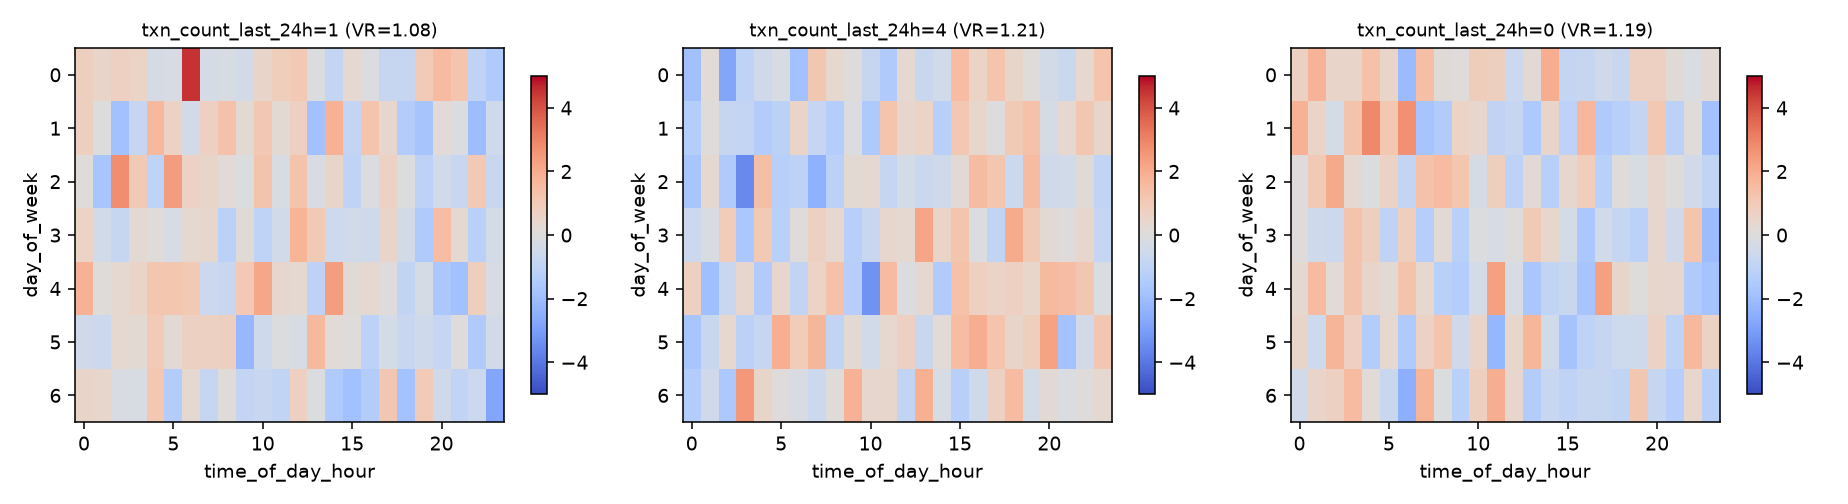

In [10]:
numeric_cols = [c for c in NUMERIC_COLUMNS if c not in TIME_COLUMNS]
cell_labels_arr = time_cell.to_numpy()


def m4c_is_integral(series) -> bool:
    vals = series.dropna().to_numpy(dtype=np.float64)
    return bool(np.all(np.equal(np.mod(vals, 1.0), 0.0)))


m4c_integral_cols = [c for c in numeric_cols if m4c_is_integral(frame[c])]
print("integral features (value counting):", m4c_integral_cols)

M4C_K = 10
M4C_MIN_EXPECTED_PER_CELL = 20.0
M4C_VR_EXCESS = 1.33
M4C_MAX_Z = 4.5
mean_cell_n = len(frame) / 168.0

m4c_omnibus_rows: list[dict[str, object]] = []
for col in tqdm(m4c_integral_cols, desc="m4c omnibus raw levels"):
    observed, null = mi_vs_null(frame[col], time_cell)
    chi2_i, p_i, dof_i, v_i = chi2_independence(frame[col], time_cell)
    h_col = entropy(frame[col])
    verdict = interaction_verdict(observed, null.max(), v_i, V_FLOOR)
    m4c_omnibus_rows.append(
        {
            "feature": col,
            "n_levels": int(frame[col].nunique()),
            "mi_nats": observed,
            "null_mi_max": float(null.max()),
            "mi_share_of_feature": observed / h_col,
            "chi2": chi2_i,
            "p_value": p_i,
            "cramers_v": v_i,
            "verdict": verdict,
        }
    )
m4c_omnibus = pd.DataFrame(m4c_omnibus_rows)
print(m4c_omnibus.round(5).to_string(index=False))
omnibus_path = tables_dir / "m4c_omnibus_tests.csv"
m4c_omnibus.to_csv(omnibus_path, index=False)
print("saved", omnibus_path)
print(DELIMITER_VALUE)

m4c_value_rows: list[dict[str, object]] = []
m4c_z_store: dict[tuple[str, object], dict[tuple[int, int], float]] = {}
rng_m4c = np.random.default_rng(23)
for col in tqdm(m4c_integral_cols, desc="m4c per-value z"):
    shares = frame[col].value_counts(normalize=True)
    testable = shares.loc[shares * mean_cell_n >= M4C_MIN_EXPECTED_PER_CELL]
    if len(testable) <= 2 * M4C_K:
        chosen = list(testable.index)
    else:
        chosen = list(testable.index[:M4C_K]) + list(testable.index[-M4C_K:])
    counts_obs = pd.crosstab(time_cell, frame[col])
    counts_null = pd.crosstab(
        pd.Series(rng_m4c.permutation(cell_labels_arr)), frame[col].to_numpy()
    )
    n_obs = counts_obs.sum(axis=1).to_numpy(dtype=np.float64)
    n_null = counts_null.sum(axis=1).to_numpy(dtype=np.float64)
    cell_ids = []
    for k in counts_obs.index:
        hour_s, dow_s = str(k).split("_")
        cell_ids.append((int(dow_s), int(hour_s)))
    for value in chosen:
        p = float(shares.loc[value])
        se_scale = np.sqrt(p * (1.0 - p))
        z_obs = (
            counts_obs[value].to_numpy(dtype=np.float64) / n_obs - p
        ) * np.sqrt(n_obs) / se_scale
        z_null = (
            counts_null[value].to_numpy(dtype=np.float64) / n_null - p
        ) * np.sqrt(n_null) / se_scale
        vr_obs = float(np.mean(z_obs**2))
        vr_null = float(np.mean(z_null**2))
        max_obs = float(np.max(np.abs(z_obs)))
        max_null = float(np.max(np.abs(z_null)))
        flagged = (vr_obs > max(M4C_VR_EXCESS, vr_null + 0.33)) or (
            max_obs > M4C_MAX_Z and max_null <= M4C_MAX_Z
        )
        m4c_value_rows.append(
            {
                "feature": col,
                "value": value,
                "share": p,
                "expected_per_cell": p * mean_cell_n,
                "vr_observed": vr_obs,
                "max_abs_z_observed": max_obs,
                "vr_null": vr_null,
                "max_abs_z_null": max_null,
                "flagged": flagged,
            }
        )
        m4c_z_store[(col, value)] = {
            cell_ids[gi]: float(z_obs[gi]) for gi in range(len(cell_ids))
        }
m4c_value_table = pd.DataFrame(m4c_value_rows)
value_path = tables_dir / "m4c_value_z.csv"
m4c_value_table.to_csv(value_path, index=False)
print("saved", value_path)
print(DELIMITER_VALUE)
worst_values = m4c_value_table.loc[
    m4c_value_table.groupby("feature")["vr_observed"].idxmax()
].sort_values("vr_observed", ascending=False)
print("worst value per feature (by observed variance ratio)")
print(
    worst_values[
        [
            "feature",
            "value",
            "share",
            "expected_per_cell",
            "vr_observed",
            "vr_null",
            "max_abs_z_observed",
            "flagged",
        ]
    ].round(4).to_string(index=False)
)
print(DELIMITER_VALUE)
flagged_values = m4c_value_table.loc[m4c_value_table["flagged"]]
print("flagged (feature, value) pairs:", len(flagged_values))
if len(flagged_values):
    print(
        flagged_values[
            ["feature", "value", "share", "vr_observed", "vr_null", "max_abs_z_observed"]
        ].round(4).to_string(index=False)
    )
print(DELIMITER_VALUE)
all_z_m4c = np.concatenate(
    [np.array(list(v.values()), dtype=np.float64) for v in m4c_z_store.values()]
)
print(f"z sanity over {len(all_z_m4c)} values: mean={all_z_m4c.mean():.3f} sd={all_z_m4c.std():.3f}")

plot_dir = get_script_plot_dir(NOTEBOOK_STEM, section="m4c_value_counts")
top_show = m4c_value_table.sort_values(
    ["flagged", "vr_observed"], ascending=[False, False]
).head(3)
n_show = len(top_show)
fig, axes = plt.subplots(1, n_show, figsize=(4.4 * n_show, 3.6))
if n_show == 1:
    axes = [axes]
for ax, (_i, row) in zip(axes, top_show.iterrows()):
    grid_z = np.full((7, 24), np.nan)
    for (dow_i, hour_i), z_val in m4c_z_store[(row["feature"], row["value"])].items():
        grid_z[dow_i, hour_i] = z_val
    im = ax.imshow(grid_z, aspect="auto", cmap="coolwarm", vmin=-5.0, vmax=5.0)
    ax.set_title(
        f"{row['feature']}={row['value']} (VR={row['vr_observed']:.2f})",
        fontsize=9,
    )
    ax.set_xlabel(HOUR_COL)
    ax.set_ylabel(DOW_COL)
    fig.colorbar(im, ax=ax, shrink=0.85)
fig.tight_layout()
m4c_plot = plot_dir / "m4c_top_deviation_heatmaps.png"
fig.savefig(m4c_plot, dpi=140)
print("saved", m4c_plot)


## Takeaway: M4c value counting

1. **Omnibus: every integer-valued feature is independent of time on its raw levels.** MI never beats the shuffle null: `customer_age` 0.00752 vs 0.00763 null max, `card_age_months` 0.00533 vs 0.00537, `txn_count_last_24h`, `cvv_retry_count`, `prior_disputes` all below null; Cramer's V ~ 0.015 everywhere. This closes M4's blind spot: deciles blurred the tie piles where these features live, raw levels do not, and the answer is still independence.

2. **Per-value layer: no pattern.** The yardstick is perfectly calibrated (z mean -0.000, sd 0.994 over 8,904 values). Worst variance ratio per feature sits at 1.05-1.21, inside the 1 +/- 0.33 band. One lone cell crossed the 4.5 line (`txn_count_last_24h = 1`, |z| 4.51) while its VR stayed flat (1.08 vs null 1.12): a single blip among 168 cells, not a systematic deviation.

3. **Verdict.** Neither the head values, the tail values, nor any single level of the counting features moves with the clock beyond noise. Together with M4b's finding (only a mild amount wiggle), the M4 family is settled: drop the raw time features.
